In [6]:
import os
import time
import warnings

import matplotlib.pyplot as plt

import torch
import torchvision.models as models
import torchvision.transforms.functional as F

from torch.export import export
from torchvision.io import decode_image

from executorch import version
from executorch.runtime import Runtime
from executorch.exir import to_edge_transform_and_lower
from executorch.backends.xnnpack.partition.xnnpack_partitioner import XnnpackPartitioner

warnings.simplefilter("ignore", FutureWarning)
print("Executorch version: ", version.__version__)

model_constructors = [
    models.segmentation.deeplabv3_resnet50,
    models.segmentation.deeplabv3_resnet101,
    models.segmentation.deeplabv3_mobilenet_v3_large,
    models.segmentation.lraspp_mobilenet_v3_large,
    models.segmentation.fcn_resnet50,
    models.segmentation.fcn_resnet101,
]
model_weights = [
    models.segmentation.DeepLabV3_ResNet50_Weights.DEFAULT,
    models.segmentation.DeepLabV3_ResNet101_Weights.DEFAULT,
    models.segmentation.DeepLabV3_MobileNet_V3_Large_Weights.DEFAULT,
    models.segmentation.LRASPP_MobileNet_V3_Large_Weights.DEFAULT,
    models.segmentation.FCN_ResNet50_Weights.DEFAULT,
    models.segmentation.FCN_ResNet101_Weights.DEFAULT,
]

Executorch version:  1.1.0


In [2]:
# Resize size used for semantic segmentation models in torchvision, defined as
# `resize_size` parameter in `transforms` field of the `WeightsEnum` classes:
# - https://docs.pytorch.org/vision/main/_modules/torchvision/models/segmentation/deeplabv3.html#DeepLabV3_MobileNet_V3_Large_Weights
# - https://docs.pytorch.org/vision/main/_modules/torchvision/models/segmentation/deeplabv3.html#DeepLabV3_ResNet101_Weights
# - https://docs.pytorch.org/vision/main/_modules/torchvision/models/segmentation/deeplabv3.html#DeepLabV3_ResNet50_Weights
# - https://docs.pytorch.org/vision/main/_modules/torchvision/models/segmentation/fcn.html#FCN_ResNet101_Weights
# - https://docs.pytorch.org/vision/main/_modules/torchvision/models/segmentation/fcn.html#FCN_ResNet50_Weights
# - https://docs.pytorch.org/vision/main/_modules/torchvision/models/segmentation/lraspp.html#LRASPP_MobileNet_V3_Large_Weights
RESIZE_SIZE = (520, 520)

# Directory to store the exported .pte files
EXPORT_DIR = "exports"

In [3]:
print("Exporting models...")

for constructor, weights in zip(model_constructors, model_weights):
    model = constructor(weights=weights).eval()
    inputs = (torch.randn(1, 3, *RESIZE_SIZE),)

    program = to_edge_transform_and_lower(export(model, inputs), partitioner=[XnnpackPartitioner()])
    program = program.to_executorch()

    with open(f"{EXPORT_DIR}/{constructor.__name__}.pte", "wb") as f:
        f.write(program.buffer)
    print(f"Exported {constructor.__name__}")

Exporting models...
Exported deeplabv3_resnet50
Exported deeplabv3_resnet101
Exported deeplabv3_mobilenet_v3_large
Exported lraspp_mobilenet_v3_large
Exported fcn_resnet50
Exported fcn_resnet101


In [4]:
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

print("Verifying models...")

for constructor, weights in zip(model_constructors, model_weights):
    print(constructor.__name__.upper())

    # --- ExecuTorch Inference ---
    img = decode_image("assets/dog.png").unsqueeze(0)
    img = F.resize(img, RESIZE_SIZE, interpolation=F.InterpolationMode.BILINEAR, antialias=True)
    img = F.convert_image_dtype(img, torch.float)
    img = F.normalize(img, mean=IMAGENET_MEAN, std=IMAGENET_STD)

    t = time.perf_counter()
    runtime = Runtime.get()
    program = runtime.load_program(f"{EXPORT_DIR}/{constructor.__name__}.pte")
    # NOTE: Model returns a list of outputs, we only care about the first one
    # which contains a tensor of multinomial logits per-pixel of shape `(1,
    # num_classes=21, H, W)`. The second output contains the auxiliary loss
    # values per-pixel.
    output, *_ = program.load_method("forward").execute([img])
    t = time.perf_counter() - t

    print(
        f"Model size: {os.path.getsize(f'{EXPORT_DIR}/{constructor.__name__}.pte') / 1024 / 1024:.2f}MB\n"
        f"Run successfully via ExecuTorch in {t:.2f} seconds.\n"
    )

    # --- PyTorch Eager Reference ---
    img = decode_image("assets/dog.png").unsqueeze(0)
    img = F.resize(img, RESIZE_SIZE, interpolation=F.InterpolationMode.BILINEAR, antialias=True)

    ref_model = constructor(weights=weights).eval()
    preprocess = weights.transforms()
    ref_output = ref_model(preprocess(img))["out"]

    torch.testing.assert_close(output, ref_output, rtol=1e-3, atol=1e-4)
    print("Comparison passed!")

[program.cpp:154] InternalConsistency verification requested but not available
[

Verifying models...
DEEPLABV3_RESNET50


cpuinfo_utils.cpp:71] Reading file /sys/devices/soc0/image_version
[cpuinfo_utils.cpp:87] Failed to open midr file /sys/devices/soc0/image_version
[cpuinfo_utils.cpp:167] Number of efficient cores 4


Model size: 160.18MB
Run successfully via ExecuTorch in 1.75 seconds.



[program.cpp:154] InternalConsistency verification requested but not available


Comparison passed!
DEEPLABV3_RESNET101
Model size: 232.58MB
Run successfully via ExecuTorch in 2.45 seconds.



... (4 outputs left out)

[program.cpp:154] InternalConsistency verification requested but not available


Comparison passed!
FCN_RESNET50
Model size: 134.69MB
Run successfully via ExecuTorch in 1.34 seconds.



[program.cpp:154] InternalConsistency verification requested but not available


Comparison passed!
FCN_RESNET101
Model size: 207.09MB
Run successfully via ExecuTorch in 2.16 seconds.

Comparison passed!


Visual inspection...


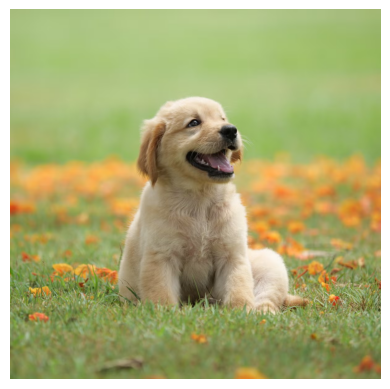

[program.cpp:154] InternalConsistency verification requested but not available


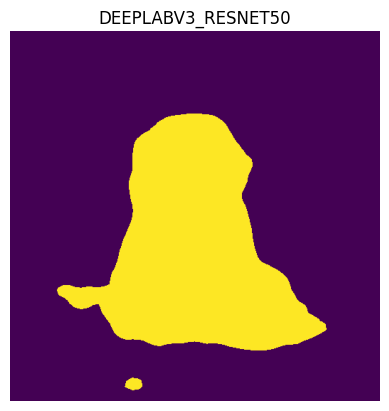

[program.cpp:154] InternalConsistency verification requested but not available


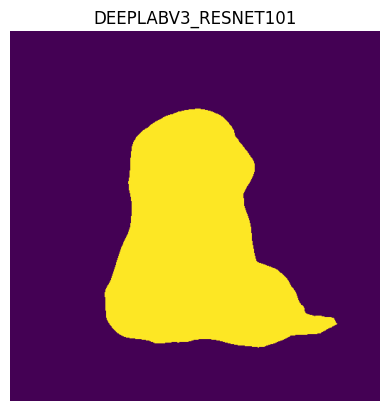

[program.cpp:154] InternalConsistency verification requested but not available


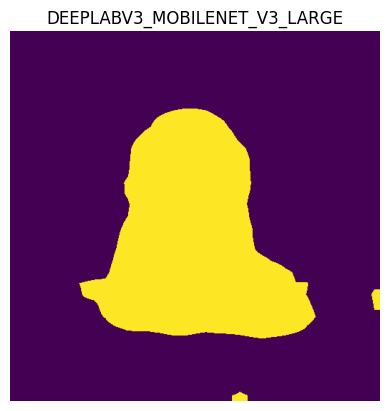

[program.cpp:154] InternalConsistency verification requested but not available


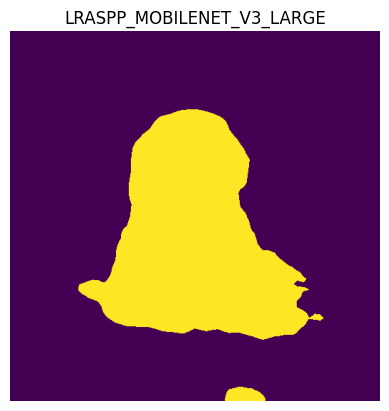

[program.cpp:154] InternalConsistency verification requested but not available


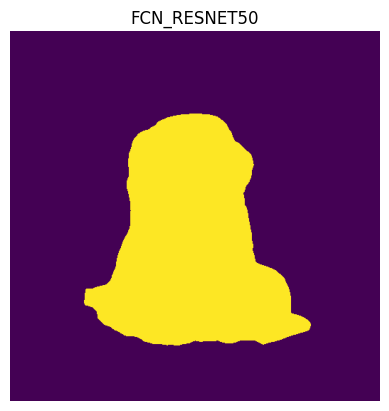

[program.cpp:154] InternalConsistency verification requested but not available


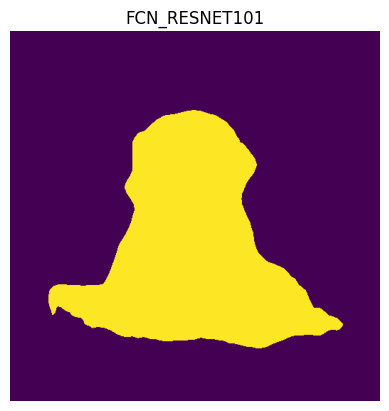

In [5]:
print("Visual inspection...")

img = decode_image("assets/dog.png")
plt.imshow(F.to_pil_image(img))
plt.axis("off")
plt.show()

for constructor in model_constructors:
    img = decode_image("assets/dog.png").unsqueeze(0)
    img = F.resize(img, RESIZE_SIZE, interpolation=F.InterpolationMode.BILINEAR, antialias=True)
    img = F.convert_image_dtype(img, torch.float)
    img = F.normalize(img, mean=IMAGENET_MEAN, std=IMAGENET_STD)

    runtime = Runtime.get()
    program = runtime.load_program(f"{EXPORT_DIR}/{constructor.__name__}.pte")
    output, *_ = program.load_method("forward").execute([img])

    normalized_masks = output.softmax(dim=1)
    class_to_idx = {cls: idx for (idx, cls) in enumerate(weights.meta["categories"])}
    mask = normalized_masks[0, class_to_idx["dog"]]

    plt.imshow(F.to_pil_image(mask), vmin=0, vmax=1)
    plt.title(constructor.__name__.upper())
    plt.axis("off")
    plt.show()